# **Regresión lineal**

La regresión lineal es un modelo que "aprende". Todo lo anterior (K-Means, análisis de sentimiento) usaba modelos ya entrenados o agrupaba datos. Aquí, por primera vez, se va a ver cómo un modelo ajusta sus parámetros para reducir su error. Eso es una de las tareas fundamentales del machine learning.

Por ejemplo,

```
"Tengo datos de pisos: metros cuadrados y precio.
Quiero predecir cuánto costará un piso de 80 m²
que no está en la lista."

"La regresión lineal es eso:
dibujar la línea que mejor se ajusta a los datos,
y usarla para predecir valores nuevos."
```

La ecuación es y = a * x + b. El modelo no "entiende" pisos, solo busca los valores de a y b que hacen que la recta pase lo más cerca posible de todos los puntos.


# **¿Cómo aprende el modelo?**

1. El modelo empieza con a y b aleatorios (o a cero).
2. Calcula la predicción para cada dato: y_pred = a * x + b.
3. Compara con el valor real: error = y_real - y_pred.
4. Ajusta a y b un poco para reducir ese error.
5. Este proceso se repite muchas veces.

Ese proceso se llama **descenso de la gradiente**: "el modelo prueba, mide cuánto se equivoca, y corrige; una y otra vez."

En este proceso hay dos valores importantes:

**Learning rate**: cuánto se corrige en cada paso. Si es muy pequeño, tarda mucho. Si es muy grande, se pasa de largo y no converge.

**Epochs**: cuántas veces se repite el proceso. Pocas, y no aprende. Demasiadas, y puede sobreajustar.

Estos hiperparámetros determinan si el modelo converge, tarda demasiado o diverge.

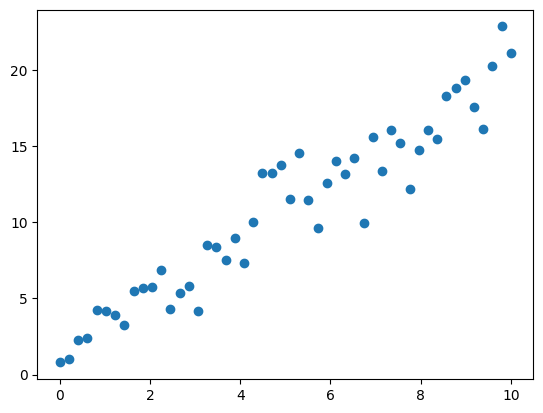

In [25]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(238)
X = np.linspace(0, 10, 50)
y = 2 * X + 1 + np.random.randn(50) * 2
plt.scatter(X, y)
plt.show()

In [26]:
type(X)

numpy.ndarray

In [27]:
type(y)

numpy.ndarray

In [28]:
X[:10]

array([0.        , 0.20408163, 0.40816327, 0.6122449 , 0.81632653,
       1.02040816, 1.2244898 , 1.42857143, 1.63265306, 1.83673469])

In [29]:
y[:10]

array([0.79104281, 1.0212283 , 2.25247534, 2.42682996, 4.25245237,
       4.16108715, 3.94257182, 3.27698626, 5.45959711, 5.69119986])

In [30]:
# === hiperparámetros ===
learning_rate = 0.001 #usar 0.1, 0.5, 0.0001
epochs = 50           #usar 10, 50, 100
# ============================================

a, b = 0.0, 0.0
for _ in range(epochs):
    y_pred = a * X + b
    da = -2 * np.mean(X * (y - y_pred))
    db = -2 * np.mean(y - y_pred)
    a -= learning_rate * da
    b -= learning_rate * db

In [31]:
# se han aprendido los coeficientes a y b
print(f"{a:.2f} * x + {b:.2f} = y")

1.98 * x + 0.33 = y


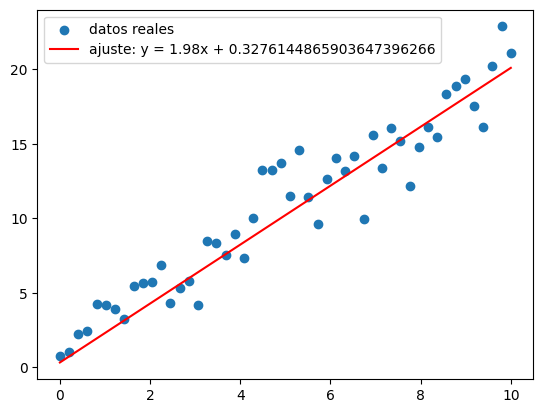

In [32]:
# se representan los puntos y la recta
plt.scatter(X, y, label="datos reales")
plt.plot(X, a * X + b, color="red", label=f"ajuste: y = {a:2.2f}x + {b:.22f}")
plt.legend()
plt.show()

In [33]:
# evaluar con datos que el modelo nunca ha visto
# aquí realizamos la evaluación de todos los datos de prueba
# el resultado se convierte en un array unidimensional
y_pred = a * X.flatten() + b
# aquí se calcula el error cuadrático medio
# np.mean: calcula la media de los errores al cuadrado
mse_test = np.mean((y_pred - y) ** 2)

print(f"Error cuadrático medio en PRUEBA: {mse_test:,.0f} €²")
print(f"Error absoluto medio en PRUEBA: {np.mean(np.abs(y_pred - y)):,.0f} €")

Error cuadrático medio en PRUEBA: 3 €²
Error absoluto medio en PRUEBA: 1 €


```
"Si mañana llega un piso de 200 m²,
¿confiarías en la predicción del modelo?
¿Qué pasaría si el modelo solo ha visto
pisos de 40 a 100 m²? ¿Por qué?"
```

La respuesta introduce un concepto crucial: el modelo solo es fiable dentro del rango de datos que ha visto. Fuera de ahí, extrapola y puede decir barbaridades. Eso conecta con la idea de incertidumbre que ya se vio en K-Means: el modelo no sabe que no sabe.



---



El dataset "Properties for sale or rent in Spain" de Zenodo contiene 542 registros de propiedades en España con 19 columnas que incluyen Sale_Price (precio de venta en euros), Surface (superficie en m²), Bedrooms, Bathrooms, Year_Construction, City y Property_Type. Es perfecto porque:

    Tiene la relación directa superficie → precio para la regresión lineal.

    Los datos son reales del mercado español.

    Se carga directamente en Colab desde el enlace de Zenodo sin necesidad de registrarse.



In [34]:
import pandas as pd

url = "https://zenodo.org/records/14028180/files/properties_Spain.csv"
df = pd.read_csv(url)
type(df)

pandas.core.frame.DataFrame

In [35]:
df.head()

,Energy_Consumption,Reference,Heating,Country,City,Zone,Energy_Class,Publish_date,Sale_Price,Floor,Street,Bedrooms,Elevator,Bathrooms,Year_Construction,Surface,Autonomous_Community,Contrat,Property_Type
0,"42,06 kW h/m&sup2; año",594509,NaN,es,Almería,NaN,g,2024-09-13 17:32:47,105000,1,Calle Quinta Avenida,3 dorm.,NaN,1 baño,1969,88.0,Andalucía,venta,Popular
1,NaN,599139,NaN,es,Almería,NaN,NaN,2024-10-25 19:44:05,97990,Baja,C. Cámaras,3 dorm.,NaN,1 baño,1960,111.0,Andalucía,venta,Popular
2,NaN,599242,NaN,es,Almería,NaN,NaN,2024-10-25 19:26:17,59990,NaN,C. Zagal,3 dorm.,NaN,NaN,1954,51.0,Andalucía,venta,Media
3,NaN,598061,NaN,es,Almería,NaN,NaN,2024-10-18 16:40:37,119000,2,Calle Marchales,3 dorm.,NaN,1 baño,1974,106.0,Andalucía,venta,Popular
4,NaN,532627,NaN,es,Almería,NaN,NaN,2024-10-16 09:53:10,159500,NaN,C. Maldonado Entrena,4 dorm.,NaN,2 baños,1975,172.0,Andalucía,venta,Popular


In [36]:
# limpieza de datos
# se borran los registros que tengan valores nulos en alguno de los dos campos indicados
df = df.dropna(subset=["Sale_Price", "Surface"])
# se filtran los registros que en el campo indicado tengan el valor especificado
df = df[df["Contrat"] == "venta"]
# filtrar valores extremos poco realistas: outliers
df = df[(df["Sale_Price"] > 10000) & (df["Sale_Price"] < 2000000)]
df = df[(df["Surface"] > 20) & (df["Surface"] < 500)]

In [37]:
# se visualizan los campos indicados de los primeros registros
df[["Sale_Price", "Surface", "Bedrooms", "Bathrooms"]].head()

,Sale_Price,Surface,Bedrooms,Bathrooms
0,105000,88.0,3 dorm.,1 baño
1,97990,111.0,3 dorm.,1 baño
2,59990,51.0,3 dorm.,NaN
3,119000,106.0,3 dorm.,1 baño
4,159500,172.0,4 dorm.,2 baños


In [38]:
print(f"Número de viviendas: {len(df)}")
print(df[["Sale_Price", "Surface"]].describe())

Número de viviendas: 428
         Sale_Price     Surface
count  4.280000e+02  428.000000
mean   2.008351e+05  114.151869
std    1.723698e+05   63.258422
min    1.850000e+04   27.000000
25%    9.497500e+04   75.000000
50%    1.559500e+05   94.000000
75%    2.590000e+05  130.500000
max    1.890000e+06  454.000000


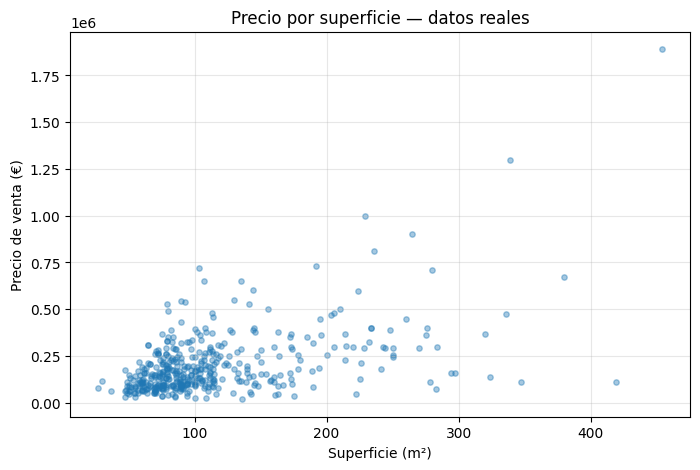

In [39]:
# representamos gráficamente los puntos
plt.figure(figsize=(8, 5))
plt.scatter(df["Surface"], df["Sale_Price"], alpha=0.4, s=15)
plt.xlabel("Superficie (m²)")
plt.ylabel("Precio de venta (€)")
plt.title("Precio por superficie — datos reales")
plt.grid(True, alpha=0.3)
plt.show()

In [40]:
# transformando los datos
# se normalizan para que se mas fácil tratarlos
print(type(df["Surface"]))
print(type(df["Surface"].values))
print(type(df["Surface"].values.reshape(-1, 1)))
print(df["Surface"].values[:5])
print(df["Surface"].values.reshape(-1, 1)[:5])
print("dimensiones", df["Surface"].values.ndim)
print("forma", df["Surface"].values.shape)
print("tamaño", df["Surface"].values.size)
print("dimensiones", df["Surface"].values.reshape(-1, 1).ndim)
print("forma", df["Surface"].values.reshape(-1, 1).shape)
print("tamaño", df["Surface"].values.reshape(-1, 1).size)

<class 'pandas.core.series.Series'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
[ 88. 111.  51. 106. 172.]
[[ 88.]
 [111.]
 [ 51.]
 [106.]
 [172.]]
dimensiones 1
forma (428,)
tamaño 428
dimensiones 2
forma (428, 1)
tamaño 428


In [41]:
from sklearn.model_selection import train_test_split

#los datos de entrada son el array unidimensional
#que se debe transformar en
#un array bidimensional
#es habitual nombrar X el conjunto de datos e y el conjunto de resultados
X = df["Surface"].values.reshape(-1, 1)  # entrada, debe ser bidimensional
y = df["Sale_Price"].values              # salida, unidimensional

# el 80% de los datos para entrenar y el 20% de los datos para evaluar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Entrenamiento: {len(X_train)} viviendas")
print(f"Prueba: {len(X_test)} viviendas")

Entrenamiento: 342 viviendas
Prueba: 86 viviendas


In [42]:
# ================================================
# MODIFICA ESTOS DOS NÚMEROS Y EJECUTA
learning_rate = 0.0001    # prueba con 0.1, 0.000001, 0.00000001
epochs = 10                # prueba con 5, 20, 100
# ================================================

# Parámetros iniciales
a = 0.0   # pendiente
b = 0.0   # ordenada en el origen

n = len(X_train)

for epoch in range(epochs):
    # Predicción
    y_pred = a * X_train.flatten() + b

    # Error
    error = y_pred - y_train

    # Gradientes
    da = (2 / n) * np.sum(error * X_train.flatten())
    db = (2 / n) * np.sum(error)

    # Actualizar parámetros
    a = a - learning_rate * da
    b = b - learning_rate * db

    # Mostrar error cada cierto número de épocas
    if epoch % max(1, epochs // 5) == 0:
        mse = np.mean(error ** 2)
        print(f"Época {epoch:3d} | MSE: {mse:,.0f} | a: {a:.2f} | b: {b:.2f}")

print(f"\nParámetros finales: a = {a:.2f}, b = {b:.2f}")
print(f"Recta aprendida: precio = {a:.2f} × superficie + {b:.2f}")

Época   0 | MSE: 72,485,852,612 | a: 5850.83 | b: 40.63
Época   2 | MSE: 1,584,496,570,230 | a: 24459.76 | b: 168.77
Época   4 | MSE: 47,869,031,635,843 | a: 127418.30 | b: 869.42
Época   6 | MSE: 1,464,696,398,707,736 | a: 697061.50 | b: 4737.69
Época   8 | MSE: 44,835,549,850,262,080 | a: 3848751.09 | b: 26131.53

Parámetros finales: a = -9047098.54, b = -61397.78
Recta aprendida: precio = -9047098.54 × superficie + -61397.78


In [43]:
pruebas = [(0.1, 10), (0.5, 10), (0.0001, 10), (0.00001, 10), (0.00001, 50), (0.00001, 100)]

for lr, ep in pruebas:
    a, b = 0.0, 0.0
    for epoch in range(ep):
        y_pred = a * X_train.flatten() + b
        error = y_pred - y_train
        da = (2 / n) * np.sum(error * X_train.flatten())
        db = (2 / n) * np.sum(error)
        a = a - lr * da
        b = b - lr * db

    mse = np.mean((a * X_train.flatten() + b - y_train) ** 2)
    mae_test = np.mean(np.abs(a * X_test.flatten() + b - y_test))
    print(f"LR={lr} | epochs={ep} | MSE: {mse:,.0f} | a: {a:.2f} | b: {b:.2f} | error prueba: {mae_test:,.0f} €")

LR=0.1 | epochs=10 | MSE: 1,629,480,373,395,084,745,747,573,357,353,791,897,229,533,939,102,499,342,769,396,512,597,502,825,857,024,000 | a: -311792740539507226938790858591121178624.00 | b: -2116284723482465466899126306067185664.00 | error prueba: 36,083,062,259,713,906,321,912,366,572,395,649,040,384 €
LR=0.5 | epochs=10 | MSE: 156,142,988,060,184,393,886,688,131,365,245,992,193,774,739,624,832,519,328,174,592,433,903,911,107,001,387,575,562,874,126,336 | a: -3052127524295420984905621059079959073169342464.00 | b: -20716232336295582777709692203448241882136576.00 | error prueba: 353,215,752,532,197,129,014,774,508,156,498,924,405,700,689,920 €
LR=0.0001 | epochs=10 | MSE: 1,372,471,486,882,489,856 | a: -9047098.54 | b: -61397.78 | error prueba: 1,047,191,733 €
LR=1e-05 | epochs=10 | MSE: 21,438,314,124 | a: 1715.95 | b: 12.56 | error prueba: 108,464 €
LR=1e-05 | epochs=50 | MSE: 21,423,770,024 | a: 1745.35 | b: 16.42 | error prueba: 109,722 €
LR=1e-05 | epochs=100 | MSE: 21,423,728,164 

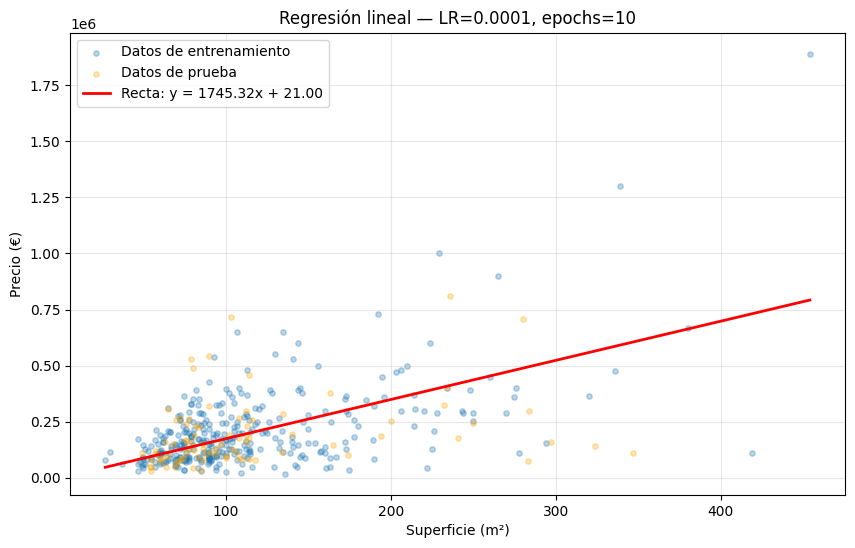

In [44]:
# representamos gráficamente la nube de puntos y la recta aprendida (el modelo)
plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, alpha=0.3, s=15, label="Datos de entrenamiento")
plt.scatter(X_test, y_test, alpha=0.3, s=15, color="orange", label="Datos de prueba")

x_line = np.linspace(X.min(), X.max(), 100)
y_line = a * x_line + b
plt.plot(x_line, y_line, color="red", linewidth=2,
         label=f"Recta: y = {a:.2f}x + {b:.2f}")

plt.xlabel("Superficie (m²)")
plt.ylabel("Precio (€)")
plt.title(f"Regresión lineal — LR={learning_rate}, epochs={epochs}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

¿Cómo funciona el algoritmo usando diferentes hiperparámetros? ¿Con qué hiperparámetros se obtiene el mejor modelo? ¿Hay algún número de épocas a partir del cual el modelo ya no aprende más?

 Con learning rate 0.1 y 0.5 el modelo no aprende: el error se dispara
(MSE enorme) y a y b salen con números gigantes. Los pasos son demasiado
grandes y se pasa de largo.
Con 0.0001 también diverge (MSE de 1.372.471.486.882.489.856 y error en
prueba de más de mil millones de €).
Con 0.00001 sí converge: MSE de 21.438 millones con 10 épocas y un error
en prueba de 108.464 €. Es el mejor learning rate de los que he probado.

Con 10 épocas el MSE ya es 21.438 millones, con 50 baja a 21.423 millones
y con 100 a 21.423 millones. Entre 50 y 100 casi no cambia nada, así que
a partir de unas 50 épocas el modelo ya no aprende más.
Además, en prueba el error no mejora (108.464 € con 10 épocas y 109.722 €
con 50 y 100).

Aun así el error en prueba sigue siendo muy alto (unos 108.000 €), porque
solo usamos la superficie y el precio depende de más cosas.

In [45]:
# evaluar con datos que el modelo nunca ha visto
# aquí realizamos la evaluación de todos los datos de prueba
# el resultado se convierte en un array unidimensional
y_test_pred = a * X_test.flatten() + b
# aquí se calcula el error cuadrático medio
# np.mean: calcula la media de los errores al cuadrado
mse_test = np.mean((y_test_pred - y_test) ** 2)

print(f"Error cuadrático medio en PRUEBA: {mse_test:,.0f} €²")
print(f"Error absoluto medio en PRUEBA: {np.mean(np.abs(y_test_pred - y_test)):,.0f} €")

Error cuadrático medio en PRUEBA: 26,772,808,829 €²
Error absoluto medio en PRUEBA: 109,722 €


¿Por qué predecir el precio solo con la superficie no es suficiente? Porque el precio también depende de la ciudad, la planta, el año de construcción, el número de habitaciones... Eso abre la puerta a la regresión lineal múltiple, donde el modelo ya no usa una sola x, sino varias. La clase LinearRegression() de scikit-learn sirve exactamente para eso, y sería el siguiente paso lógico.